# Judged Output Analysis
Analyzes RAG evaluation results across difficulty, language, context mode, and prompt variant.

In [1]:
import glob
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

Matplotlib is building the font cache; this may take a moment.


## 1. Load judged files

In [2]:
# Adjust glob pattern to load one or many judged CSVs
OUTPUTS_DIR = Path("../data")
JUDGED_PATTERN = "**/*__judged.csv"  # recursive search

files = sorted(OUTPUTS_DIR.glob(JUDGED_PATTERN))
print(f"Found {len(files)} judged file(s):")
for f in files:
    print(" ", f.relative_to(OUTPUTS_DIR))

Found 42 judged file(s):
  judge step/gemini/gemma4_26b__advanced__distractor_plus_gold__judged.csv
  judge step/gemini/gemma4_26b__simple__distractor_plus_gold__judged.csv
  judge step/gemini/multilingual_claude_sonnet4_answers__judged.csv
  judge step/gemini/multilingual_claude_sonnet4_answers_advanced__judged.csv
  judge step/gemini/multilingual_gemini31_flash_lite_answers__judged.csv
  judge step/gemini/multilingual_gemini31_flash_lite_answers_advanced__judged.csv
  judge step/gemini/multilingual_gemma4_answers__judged.csv
  judge step/gemini/multilingual_gemma4_answers_advanced__judged.csv
  judge step/gemini/multilingual_gpt54mini_answers__judged.csv
  judge step/gemini/multilingual_gpt54mini_answers_advanced__judged.csv
  judge step/gemini/multilingual_qwen36_answers__judged.csv
  judge step/gemini/multilingual_qwen36_answers_advanced__judged.csv
  judge step/gemini/qwen3.6:27b__advanced__distractor_plus_gold__judged.csv
  judge step/gemini/qwen3.6:27b__simple__distractor_plus_g

In [3]:
dfs = []
for f in files:
    tmp = pd.read_csv(f)
    # ensure source file is traceable
    if "source_file" not in tmp.columns:
        tmp["source_file"] = f.name
    dfs.append(tmp)

df = pd.concat(dfs, ignore_index=True)
print(f"Total rows loaded: {len(df)}")
df.head(3)

Total rows loaded: 176400


,language,query_id,query,distractor_id,distractor_text,distractor_title,gold_judge_text,gold_generation_text,gold_generation_id,n_positives,...,answer_with_distractor_and_gold,generation_error,judge_label,judge_reasoning,judge_raw_json,judge_error,source_file,answer_with_distractor_claude,answer_with_distractor_gemini,answer_with_distractor
0,ar,10003,من هي كليوبترا؟,1280789#30,اجبرت الظروف انطونيوس إلى الابتعاد عن الإسكندر...,تاريخ مصر اليونانية,علي الرغم من اختلاف نظرة المؤرخين حول شخصية ال...,"كليوباترا السابعة ""(باليونانية:""Κλεοπάτρα Φιλο...",55256#5,3,...,كليوباترا السابعة هي ملكة مصر (يناير 69 ق.م - ...,NaN,CORRECT,The response accurately identifies Cleopatra V...,"{""label"": ""CORRECT"", ""reasoning"": ""The respons...",NaN,gemma4_26b__advanced__distractor_plus_gold__ju...,NaN,NaN,NaN
1,ar,10003,من هي كليوبترا؟,1280789#22,في حين منعت كليوبترا لأنها أمرأة من توصيل رغبا...,تاريخ مصر اليونانية,علي الرغم من اختلاف نظرة المؤرخين حول شخصية ال...,"كليوباترا السابعة ""(باليونانية:""Κλεοπάτρα Φιλο...",55256#5,3,...,كليوباترا السابعة هي ملكة مصر (من يناير 69 ق.م...,NaN,CORRECT,The response accurately identifies Cleopatra V...,"{""label"": ""CORRECT"", ""reasoning"": ""The respons...",NaN,gemma4_26b__advanced__distractor_plus_gold__ju...,NaN,NaN,NaN
2,ar,10003,من هي كليوبترا؟,55256#40,كانت تلك اللاهوتية مقبولة في مصر، حيث ارتبطت ا...,كليوباترا,علي الرغم من اختلاف نظرة المؤرخين حول شخصية ال...,"كليوباترا السابعة ""(باليونانية:""Κλεοπάτρα Φιλο...",55256#5,3,...,كليوباترا السابعة هي ملكة مصر (ولدت في يناير 6...,NaN,INCORRECT,The model included information not found in th...,"{""label"": ""INCORRECT"", ""reasoning"": ""The model...",NaN,gemma4_26b__advanced__distractor_plus_gold__ju...,NaN,NaN,NaN


## 2. Clean & validate

In [4]:
LABELS = ["CORRECT", "ABSTAIN", "INCORRECT"]
DIFFICULTIES = ["easy", "medium", "hard"]
LABEL_COLORS = {"CORRECT": "#4caf50", "ABSTAIN": "#ff9800", "INCORRECT": "#f44336"}

df["judge_label"] = df["judge_label"].astype(str).str.strip().str.upper()
df["difficulty"]  = df["difficulty"].astype(str).str.strip().str.lower()

# keep only valid rows for label analysis
valid = df[df["judge_label"].isin(LABELS)].copy()
print(f"Valid judged rows: {len(valid)} / {len(df)}")
print(f"Missing / invalid labels: {len(df) - len(valid)}")
valid["judge_label"].value_counts()

Valid judged rows: 176357 / 176400
Missing / invalid labels: 43


judge_label
ABSTAIN      100395
CORRECT       43126
INCORRECT     32836
Name: count, dtype: int64

## 3. Overall label distribution

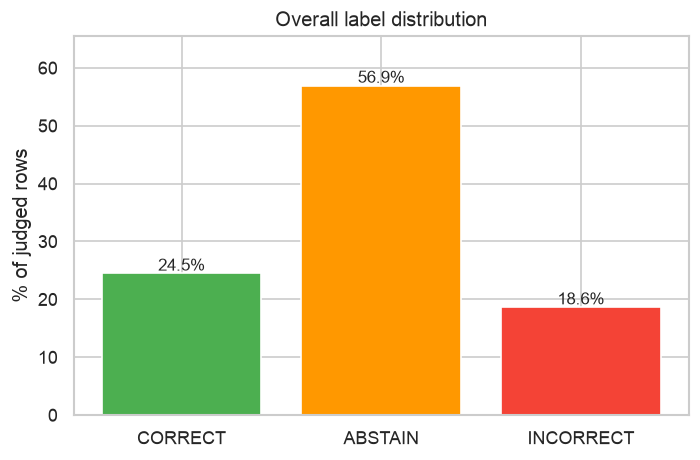

judge_label
CORRECT       43126
ABSTAIN      100395
INCORRECT     32836


In [5]:
counts = valid["judge_label"].value_counts().reindex(LABELS, fill_value=0)
pct    = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(LABELS, pct.values, color=[LABEL_COLORS[l] for l in LABELS], edgecolor="white")
for bar, v in zip(bars, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_ylabel("% of judged rows")
ax.set_title("Overall label distribution")
ax.set_ylim(0, pct.max() * 1.15)
plt.tight_layout()
plt.show()
print(counts.to_string())

## 4. Label distribution by difficulty

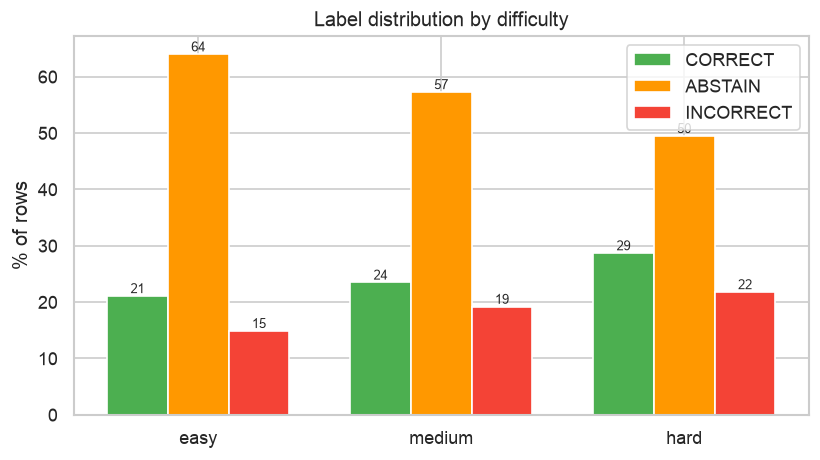

judge_label  CORRECT  ABSTAIN  INCORRECT
difficulty                              
easy            21.1     64.0       14.9
medium          23.5     57.3       19.2
hard            28.7     49.5       21.8


In [6]:
def pct_table(df, group_col, difficulties=DIFFICULTIES):
    """Return a % pivot (rows=group_col, cols=LABELS)."""
    ct = (
        df.groupby([group_col, "judge_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=LABELS, fill_value=0)
    )
    return ct.div(ct.sum(axis=1), axis=0).mul(100).round(1)


diff_valid = valid[valid["difficulty"].isin(DIFFICULTIES)].copy()
diff_pct   = pct_table(diff_valid, "difficulty").reindex(DIFFICULTIES)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(DIFFICULTIES))
w = 0.25
for i, label in enumerate(LABELS):
    vals = diff_pct[label].values
    bars = ax.bar(x + i * w, vals, w, label=label, color=LABEL_COLORS[label], edgecolor="white")
    for bar, v in zip(bars, vals):
        if v > 2:
            ax.text(bar.get_x() + bar.get_width() / 2, v + 0.5, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x + w)
ax.set_xticklabels(DIFFICULTIES)
ax.set_ylabel("% of rows")
ax.set_title("Label distribution by difficulty")
ax.legend()
plt.tight_layout()
plt.show()
print(diff_pct)

## 5. Stacked bar: difficulty × label

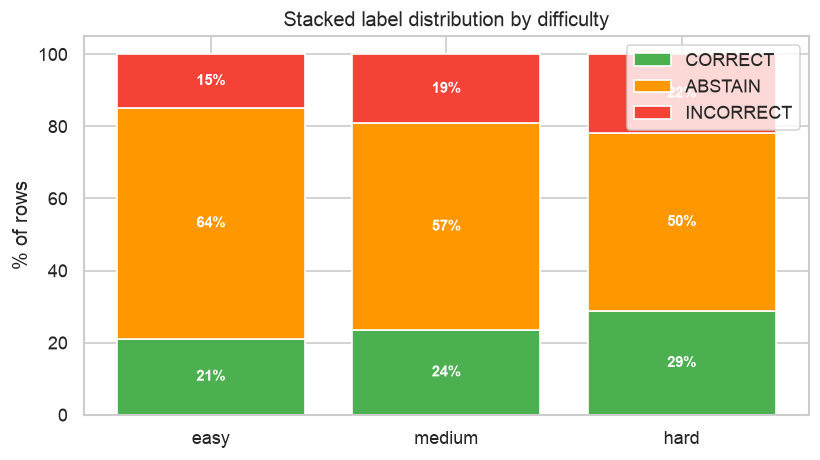

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
bottom = np.zeros(len(DIFFICULTIES))
for label in LABELS:
    vals = diff_pct.reindex(DIFFICULTIES)[label].values
    ax.bar(DIFFICULTIES, vals, bottom=bottom, label=label, color=LABEL_COLORS[label], edgecolor="white")
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 3:
            ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    bottom += vals
ax.set_ylabel("% of rows")
ax.set_title("Stacked label distribution by difficulty")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 6. Distribution by language (if multilingual)

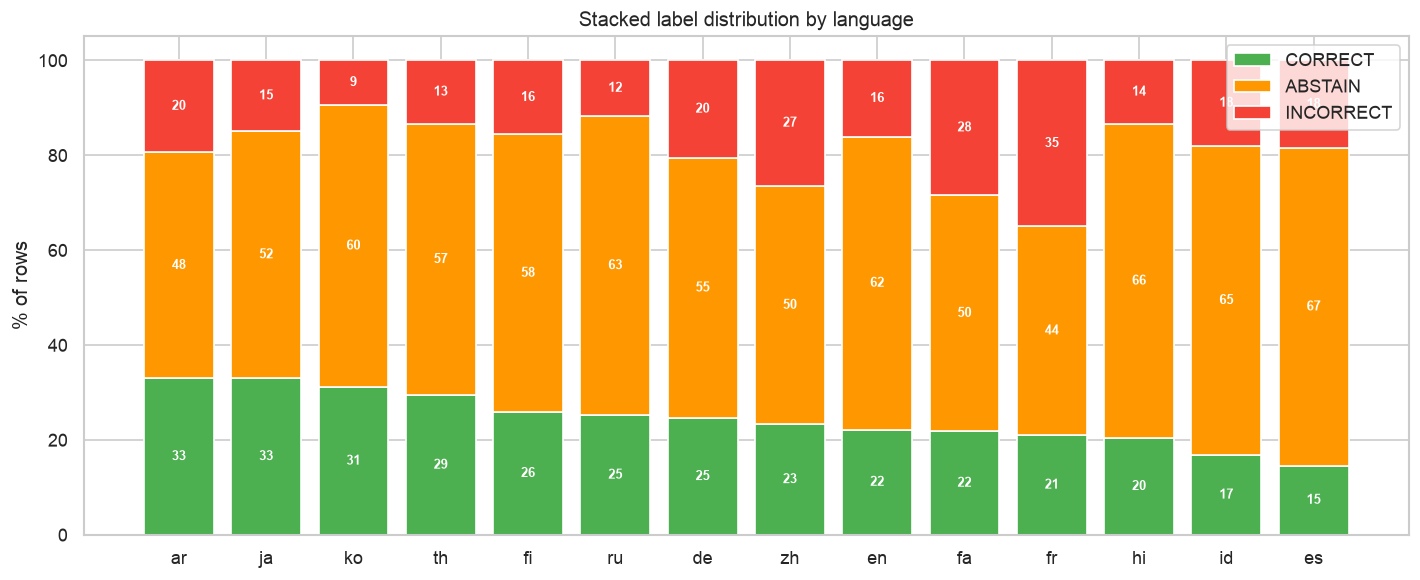

judge_label  CORRECT  ABSTAIN  INCORRECT
language                                
ar              33.0     47.6       19.5
ja              33.0     52.1       14.9
ko              31.1     59.6        9.3
th              29.4     57.3       13.3
fi              25.9     58.5       15.6
ru              25.2     63.1       11.7
de              24.6     54.9       20.5
zh              23.3     50.2       26.6
en              22.2     61.7       16.2
fa              21.8     49.8       28.4
fr              21.0     44.0       35.0
hi              20.4     66.2       13.5
id              16.8     65.2       18.0
es              14.6     66.9       18.5


In [8]:
if "language" in valid.columns and valid["language"].nunique() > 1:
    lang_pct = pct_table(valid, "language").sort_values("CORRECT", ascending=False)

    fig, ax = plt.subplots(figsize=(12, 5))
    langs = lang_pct.index.tolist()
    bottom = np.zeros(len(langs))
    for label in LABELS:
        vals = lang_pct[label].values
        ax.bar(langs, vals, bottom=bottom, label=label, color=LABEL_COLORS[label], edgecolor="white")
        for i, (v, b) in enumerate(zip(vals, bottom)):
            if v > 4:
                ax.text(i, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white", fontweight="bold")
        bottom += vals
    ax.set_ylabel("% of rows")
    ax.set_title("Stacked label distribution by language")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(lang_pct)
else:
    print("Single language or no language column — skipping.")

## 7. CORRECT rate heatmap: language × difficulty

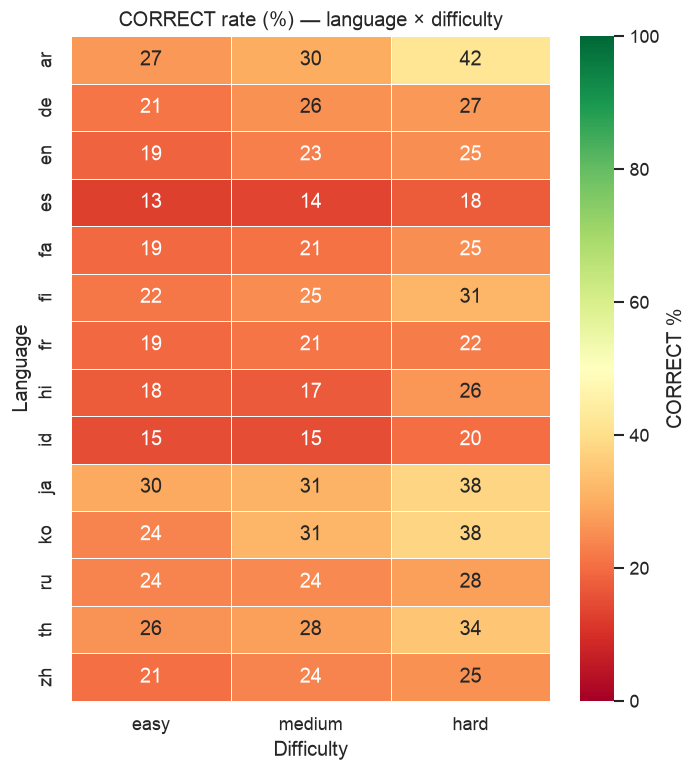

In [9]:
if "language" in valid.columns and valid["language"].nunique() > 1:
    heat = (
        valid[valid["difficulty"].isin(DIFFICULTIES)]
        .groupby(["language", "difficulty", "judge_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=LABELS, fill_value=0)
    )
    heat = heat.div(heat.sum(axis=1), axis=0).mul(100)["CORRECT"].unstack("difficulty").reindex(columns=DIFFICULTIES)

    fig, ax = plt.subplots(figsize=(6, max(4, len(heat) * 0.4 + 1)))
    sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, ax=ax,
                linewidths=0.5, cbar_kws={"label": "CORRECT %"})
    ax.set_title("CORRECT rate (%) — language × difficulty")
    ax.set_xlabel("Difficulty")
    ax.set_ylabel("Language")
    plt.tight_layout()
    plt.show()
else:
    print("Single language — skipping heatmap.")

## 8. Distribution by context mode

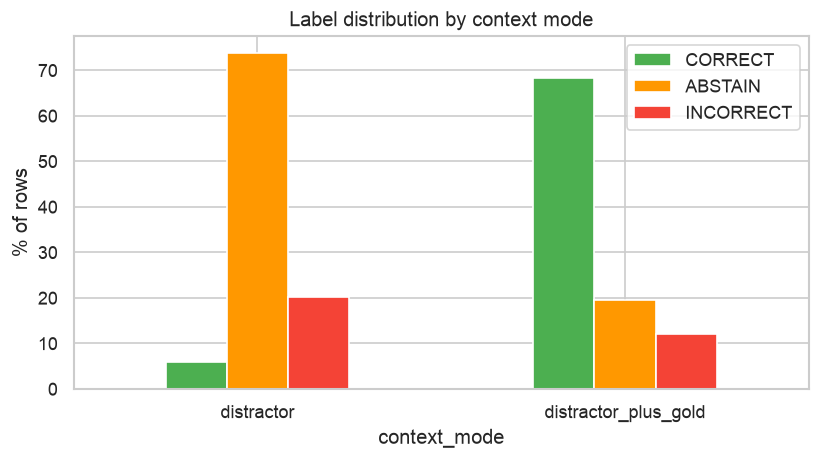

judge_label           CORRECT  ABSTAIN  INCORRECT
context_mode                                     
distractor                5.9     73.8       20.3
distractor_plus_gold     68.4     19.6       12.0


In [10]:
if "context_mode" in valid.columns and valid["context_mode"].nunique() > 1:
    mode_pct = pct_table(valid, "context_mode")
    mode_pct.plot(kind="bar", color=[LABEL_COLORS[l] for l in LABELS], edgecolor="white", figsize=(7, 4))
    plt.title("Label distribution by context mode")
    plt.ylabel("% of rows")
    plt.xticks(rotation=0)
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(mode_pct)
else:
    print("Single context_mode — skipping:", valid['context_mode'].unique() if 'context_mode' in valid.columns else 'N/A')

## 9. Distribution by prompt variant

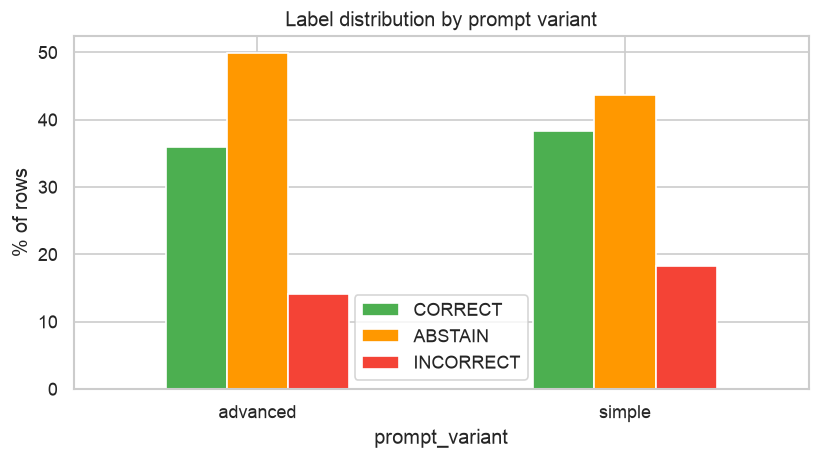

judge_label     CORRECT  ABSTAIN  INCORRECT
prompt_variant                             
advanced           36.0     49.9       14.1
simple             38.3     43.6       18.2


In [11]:
if "prompt_variant" in valid.columns and valid["prompt_variant"].nunique() > 1:
    pv_pct = pct_table(valid, "prompt_variant")
    pv_pct.plot(kind="bar", color=[LABEL_COLORS[l] for l in LABELS], edgecolor="white", figsize=(7, 4))
    plt.title("Label distribution by prompt variant")
    plt.ylabel("% of rows")
    plt.xticks(rotation=0)
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(pv_pct)
else:
    print("Single prompt_variant — skipping:", valid['prompt_variant'].unique() if 'prompt_variant' in valid.columns else 'N/A')

## 10. Multi-model comparison (if multiple models in data)

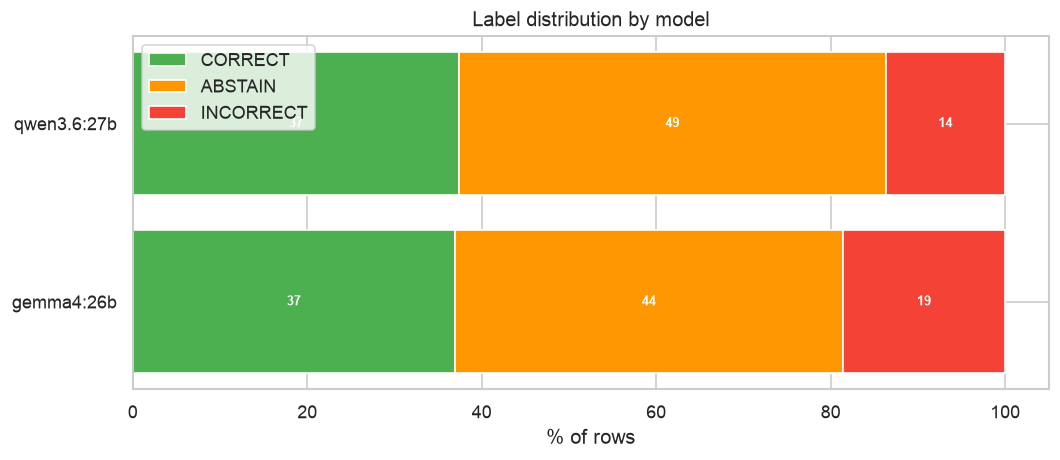

judge_label       CORRECT  ABSTAIN  INCORRECT
generation_model                             
gemma4:26b           36.9     44.5       18.6
qwen3.6:27b          37.4     48.9       13.7


In [12]:
model_col = next((c for c in ["generation_model", "model", "experiment"] if c in valid.columns), None)

if model_col and valid[model_col].nunique() > 1:
    model_pct = pct_table(valid, model_col).sort_values("CORRECT", ascending=True)

    fig, ax = plt.subplots(figsize=(9, max(4, len(model_pct) * 0.5 + 1)))
    bottom = np.zeros(len(model_pct))
    for label in LABELS:
        vals = model_pct[label].values
        ax.barh(model_pct.index, vals, left=bottom, label=label, color=LABEL_COLORS[label], edgecolor="white")
        for i, (v, b) in enumerate(zip(vals, bottom)):
            if v > 4:
                ax.text(b + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white", fontweight="bold")
        bottom += vals
    ax.set_xlabel("% of rows")
    ax.set_title("Label distribution by model")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(model_pct)
else:
    print("Single model in data — skipping.")

## 11. CORRECT rate: model × difficulty (heatmap)

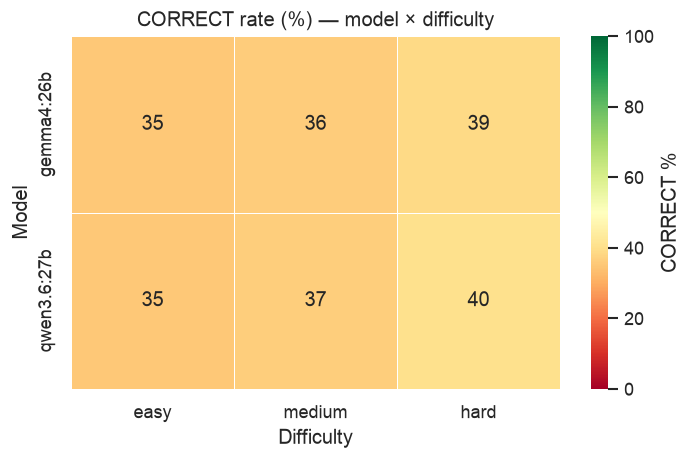

In [13]:
if model_col and valid[model_col].nunique() > 1:
    heat2 = (
        valid[valid["difficulty"].isin(DIFFICULTIES)]
        .groupby([model_col, "difficulty", "judge_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=LABELS, fill_value=0)
    )
    heat2 = heat2.div(heat2.sum(axis=1), axis=0).mul(100)["CORRECT"].unstack("difficulty").reindex(columns=DIFFICULTIES)

    fig, ax = plt.subplots(figsize=(6, max(4, len(heat2) * 0.5 + 1)))
    sns.heatmap(heat2, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, ax=ax,
                linewidths=0.5, cbar_kws={"label": "CORRECT %"})
    ax.set_title("CORRECT rate (%) — model × difficulty")
    ax.set_xlabel("Difficulty")
    ax.set_ylabel("Model")
    plt.tight_layout()
    plt.show()
else:
    print("Single model — skipping.")

## 12. Summary table

In [14]:
group_cols = [c for c in [model_col, "context_mode", "prompt_variant", "difficulty"] if c and c in valid.columns]

summary = (
    valid.groupby(group_cols)["judge_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
    .unstack(fill_value=0)
    .reindex(columns=LABELS, fill_value=0)
)
summary["n"] = valid.groupby(group_cols)["judge_label"].count()
summary

judge_label                                                      CORRECT  \
generation_model context_mode         prompt_variant difficulty            
gemma4:26b       distractor           advanced       easy            1.2   
                                                     hard           11.1   
                                                     medium          3.9   
                                      simple         easy            1.2   
                                                     hard           11.6   
                                                     medium          4.0   
                 distractor_plus_gold advanced       easy           69.1   
                                                     hard           66.6   
                                                     medium         68.0   
                                      simple         easy           69.9   
                                                     hard           66.7   
                                                     medium         69.3   
qwen3.6:27b      distractor           advanced       easy            1.1   
                                                     hard           10.5   
                                                     medium          3.7   
                                      simple         easy            2.0   
                                                     hard           14.5   
                                                     medium          5.8   
                 distractor_plus_gold advanced       easy           66.6   
                                                     hard           65.4   
                                                     medium         65.1   
                                      simple         easy           72.1   
                                                     hard           70.6   
                                                     medium         71.5   

judge_label                                                      ABSTAIN  \
generation_model context_mode         prompt_variant difficulty            
gemma4:26b       distractor           advanced       easy           83.1   
                                                     hard           61.8   
                                                     medium         74.2   
                                      simple         easy           79.5   
                                                     hard           56.8   
                                                     medium         70.0   
                 distractor_plus_gold advanced       easy           19.4   
                                                     hard           18.7   
                                                     medium         18.5   
                                      simple         easy           18.4   
                                                     hard           17.0   
                                                     medium         16.7   
qwen3.6:27b      distractor           advanced       easy           90.6   
                                                     hard           73.0   
                                                     medium         82.4   
                                      simple         easy           81.9   
                                                     hard           60.5   
                                                     medium         72.2   
                 distractor_plus_gold advanced       easy           26.1   
                                                     hard           24.4   
                                                     medium         26.1   
                                      simple         easy           16.9   
                                                     hard           16.5   
                                                     medium         16.4   

judge_label                                   